# 🦴 RSNA Knee — State-of-the-Art 21-Slice 2.5D Dataset Preprocessor (V3.0: 7 Sag + 7 Cor + 7 Ax, 224x224)

> **🎯 Master Proven Pipeline (V3.0 Specification: 21 True 2.5D Triplets @ 224px - 100% Pure DICOM)**:
> 1. **130mm Standardized Physical Center Crop**: Standardizes anatomical FOV across vendor scanners (Siemens, GE, Philips) based on `PixelSpacing` without aspect ratio distortion.
> 2. **3D Physical Coordinate Sorter**: Strictly orders slices using the standardized 3D normal vector coordinate $k = \vec{p} \cdot \vec{n}$ from `ImagePositionPatient` and `ImageOrientationPatient`.
> 3. **Per-Stack (Volume-Level) Windowing**: Contrast normalization $[P_{1.0}, P_{99.5}]$ across the whole 3D stack prevents inter-slice flicker.
> 4. **True 2.5D Triplets (7 Slices per Plane = 21 Positions Total)**:
>    - **7 Sagittal**: Central slice #4 (Index 3) covers ACL/PCL; medial slices cover Medial Meniscus; lateral slices cover Lateral Meniscus.
>    - **7 Coronal**: Covers MCL/LCL, cartilage loss, and meniscal roots.
>    - **7 Axial**: Covers Patellofemoral OA (PF OA), suprapatellar joint effusion, and Baker's cyst.
> 5. **Native ViT 224x224 Resolution**: Aligns with ViT patch grid ($16 \times 16 = 256$ tokens with DINOv2 patch 14), reduces self-attention complexity by 41% while maintaining equal dataset footprint (~13.5 GB).
> 6. **Clean Physics Metadata**: Eliminates unstratified MD5 fold splitting, preserving pure DICOM attributes for downstream stratified training.


In [1]:
# =========================================================================
# 1. Setup, Configuration & Dependencies
# =========================================================================
!pip install -q pydicom opencv-python-headless

import os, gc, glob, warnings
import numpy as np
import pandas as pd
import pydicom
import cv2
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

class CFG:
    img_size             = 224          # 224x224 Standard ViT resolution
    crop_mm              = 130.0        # 130mm standard physical knee joint FOV crop
    target_triplet_depth_mm = 3.5      # 3.5mm physical thickness per triplet step (~7mm total span)
    
    # Per-plane anatomical sampling bands (derived from clinical knee MRI geometry)
    slice_bands = {
        'Sagittal': (0.08, 0.92),       # Full joint depth for ACL and Meniscus horns (Lát 3 là tâm ACL)
        'Coronal':  (0.18, 0.82),       # Safely widened to capture MCL insertion without anchor drift
        'Axial':    (0.10, 0.90),       # Patellofemoral and posterior Baker region
    }
    
    num_slices_per_plane = 7            # 7 Sagittal + 7 Coronal + 7 Axial = 21 positions
    total_slices         = 21
    channels             = 3            # True 2.5D: 3 adjacent slices (i-1, i, i+1) per position
    num_workers          = 4            # ⚡ 4 Workers optimal for Kaggle 4-vCPU (prevents RAM spikes)
    
    # ── Input Directories & Candidate Paths ──────────────────────────────
    comp_dir_candidates = [
        '/kaggle/input/rsna-knee-abnormality-detection',
        '/kaggle/input/competitions/rsna-knee-abnormality-detection',
        '.'
    ]
    llm_candidates = [
        '/kaggle/input/rsna-knee-llm-report-labels/llm_labels_v4_blend.csv',
        '/kaggle/input/datasets/stevenleehans/rsna-knee-llm-report-labels/llm_labels_v4_blend.csv',
        './llm_labels_v4_blend.csv'
    ]
    llm_labels_csv   = next((p for p in llm_candidates if os.path.exists(p)), llm_candidates[0])
    train_series_csv = '/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv'
    
    # ── Output Paths ──────────────────────────────────────────────────────
    output_dir       = '/kaggle/working'
    out_npy_file     = 'knee_train_21slices_224.npy'
    out_meta_file    = 'train_metadata_21slices.csv'

# Locate base competition directory
BASE_COMP_DIR = '.'
for p in CFG.comp_dir_candidates:
    if os.path.exists(p) and (os.path.exists(os.path.join(p, 'train_series.csv')) or os.path.exists(os.path.join(p, 'train_images')) or os.path.exists(os.path.join(p, 'train_series'))):
        BASE_COMP_DIR = p
        break

if not os.path.exists(CFG.train_series_csv):
    alt_series = os.path.join(BASE_COMP_DIR, 'train_series.csv')
    if os.path.exists(alt_series):
        CFG.train_series_csv = alt_series

print(f'⚡ Base Directory: {BASE_COMP_DIR}')
print(f'⚡ Master Resolution: {CFG.img_size}x{CFG.img_size} | Slices: {CFG.total_slices} positions x {CFG.channels}ch (True 2.5D: 7 Sag + 7 Cor + 7 Ax)')
print(f'⚡ Physical FOV Crop: {CFG.crop_mm}mm | Per-Plane Bands: {CFG.slice_bands}')
print(f'⚡ Concurrency: {CFG.num_workers} parallel threads')


⚡ Base Directory: /kaggle/input/competitions/rsna-knee-abnormality-detection
⚡ Master Resolution: 224x224 | Slices: 21 positions x 3ch (True 2.5D: 7 Sag + 7 Cor + 7 Ax)
⚡ Physical FOV Crop: 130.0mm | Per-Plane Bands: {'Sagittal': (0.08, 0.92), 'Coronal': (0.18, 0.82), 'Axial': (0.1, 0.9)}
⚡ Concurrency: 4 parallel threads


In [2]:
# =========================================================================
# 2. Load Metadata & Series Contrast Engine
# =========================================================================
TARGET_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]
CONF_COLS = [c + '__conf' for c in TARGET_COLS]

# ── Load LLM Report Labels ────────────────────────────────────────────────
if os.path.exists(CFG.llm_labels_csv):
    df = pd.read_csv(CFG.llm_labels_csv)
    print(f'✅ Loaded LLM labels: {CFG.llm_labels_csv} | Shape: {df.shape}')
    for c in TARGET_COLS:
        if c + '__conf' not in df.columns:
            df[c + '__conf'] = (2.0 * np.abs(df[c].values - 0.5)).clip(0.0, 1.0)
else:
    train_csv_path = os.path.join(BASE_COMP_DIR, 'train.csv')
    df = pd.read_csv(train_csv_path)
    print(f'ℹ️ Loaded train.csv: {train_csv_path} | Shape: {df.shape}')

# ── Data Preparation (Fold assignment managed downstream in training pipeline) ──
print(f'ℹ️ Fold splitting removed from preprocessing: MultilabelStratifiedKFold will be assigned in training pipeline.')

# ── Load train_series metadata ────────────────────────────────────────────
train_series_df = pd.read_csv(CFG.train_series_csv)
# 🛡️ Clean Fluid_Sensitive & Fat_Suppression flags: convert NaNs, strings, floats safely to 0 or 1
if 'Fluid_Sensitive' in train_series_df.columns:
    train_series_df['Fluid_Sensitive'] = pd.to_numeric(train_series_df['Fluid_Sensitive'], errors='coerce').fillna(0).astype(int)
else:
    train_series_df['Fluid_Sensitive'] = 0

if 'Fat_Suppression' in train_series_df.columns:
    train_series_df['Fat_Suppression'] = pd.to_numeric(train_series_df['Fat_Suppression'], errors='coerce').fillna(0).astype(int)
else:
    train_series_df['Fat_Suppression'] = 0

print(f'✅ Loaded train_series: {CFG.train_series_csv} | Shape: {train_series_df.shape}')

# ── Series Selection & Contrast Classification ───────────────────────────
def classify_series_contrast(row):
    """
    Classifies series contrast from Fluid_Sensitive, Fat_Suppression flags and optional SeriesDescription.
    Accurately detects Fat-Suppression (FS) contrast even when SeriesDescription is not present.
    """
    fs_flag = int(row.get('Fluid_Sensitive', 0) == 1 or row.get('Fat_Suppression', 0) == 1)
    if fs_flag == 1:
        return 'FS'
    
    desc = str(row.get('SeriesDescription', '')).lower() if 'SeriesDescription' in row else ''
    if desc:
        if any(k in desc for k in ['fs', 'fat_sat', 'fat sat', 'fatsat', 'spair', 'stir', 'water']):
            return 'FS'
        if 't1' in desc:
            return 'T1'
        if 'pd' in desc or 't2' in desc:
            return 'NOFS_FLUID'
    return 'OTHER'

train_series_df['contrast'] = train_series_df.apply(classify_series_contrast, axis=1)

def count_series_slices(study_id, series_id, base_dir=BASE_COMP_DIR):
    """Counts real DICOM files in series folder. Returns -1 if directory is missing."""
    for sdir in [
        os.path.join(base_dir, 'train_images', str(study_id), str(series_id)),
        os.path.join(base_dir, 'train_series', str(study_id), str(series_id)),
        os.path.join(base_dir, str(study_id), str(series_id))
    ]:
        if os.path.exists(sdir):
            return len([f for f in os.listdir(sdir) if f.lower().endswith('.dcm')])
    return -1

def inspect_series_header(study_id, series_id, base_dir=BASE_COMP_DIR):
    """
    Rapidly reads first DICOM file header (stop_before_pixels=True, <0.5ms):
    Returns (is_scout, is_suboptimal, is_pd, is_t2):
    - is_scout: True if scout, loc, survey -> MUST BE ABSOLUTELY REJECTED (never accepted)
    - is_suboptimal: True if repeat, redo, motion, corrupt -> used only as fallback if no clean series, flagged
    - is_pd: True if Proton Density (clinical gold standard for knee meniscus/ligaments)
    - is_t2: True if T2 sequence
    """
    for sdir in [
        os.path.join(base_dir, 'train_images', str(study_id), str(series_id)),
        os.path.join(base_dir, 'train_series', str(study_id), str(series_id)),
        os.path.join(base_dir, str(study_id), str(series_id))
    ]:
        if os.path.exists(sdir):
            dcms = [f for f in os.listdir(sdir) if f.lower().endswith('.dcm')]
            if dcms:
                try:
                    hdr = pydicom.dcmread(os.path.join(sdir, dcms[0]), stop_before_pixels=True)
                    desc = (str(getattr(hdr, 'SeriesDescription', '')) + ' ' + 
                            str(getattr(hdr, 'ProtocolName', ''))).lower()
                    is_scout = any(k in desc for k in ['scout', 'loc', 'survey'])
                    is_suboptimal = any(k in desc for k in ['repeat', 'redo', 'motion', 'corrupt'])
                    is_pd = any(k in desc for k in ['pd', 'dp', 'proton'])
                    is_t2 = ('t2' in desc) and not is_pd
                    return is_scout, is_suboptimal, is_pd, is_t2
                except Exception:
                    pass
                return False, False, False, False
    return False, False, False, False

def get_study_series_info_map(series_df, base_dir=BASE_COMP_DIR):
    """
    Picks the optimal series for each plane via clinical safety rules:
    1. Rejects sequences with < 7 slices on disk.
    2. ABSOLUTE REJECTION OF SCOUTS: Series identified as scout/localizer/survey are NEVER accepted.
    3. SUBOPTIMAL SERIES HANDLING: Prefers clean series; only falls back to repeat/motion if no clean series exists,
       and explicitly flags 'is_suboptimal = 1' in metadata for downstream tracking.
    4. Clinical Sequence Hierarchy: Clean (10000) > FS (1000) > Proton Density (100) > T2 (20) + n_slices.
    5. Deterministic Tie-Breaker on SeriesInstanceUID string guarantees 100% stable selection.
    """
    study_map = {}
    MIN_SLICES = CFG.num_slices_per_plane  # 7 distinct slices required
    
    for study_id, group in series_df.groupby('StudyInstanceUID'):
        planes_info = {}
        for plane in ['Sagittal', 'Coronal', 'Axial']:
            sub = group[group['Anatomical_Plane'] == plane].copy()
            if len(sub) == 0:
                planes_info[plane] = {'series_id': None, 'is_fs': 0, 'is_suboptimal': 0, 'contrast': 'UNK', 'n_slices': 0}
                continue
            
            # Count physical slice files
            sub['n_slices'] = sub['SeriesInstanceUID'].apply(lambda sid: count_series_slices(study_id, sid, base_dir))
            
            # Filter candidates with at least MIN_SLICES on disk
            sub = sub[sub['n_slices'] >= MIN_SLICES].copy()
            if len(sub) == 0:
                planes_info[plane] = {'series_id': None, 'is_fs': 0, 'is_suboptimal': 0, 'contrast': 'UNK', 'n_slices': 0}
                continue
            
            # Inspect DICOM header
            header_stats = sub['SeriesInstanceUID'].apply(lambda sid: inspect_series_header(study_id, sid, base_dir))
            sub['is_scout']      = [h[0] for h in header_stats]
            sub['is_suboptimal'] = [h[1] for h in header_stats]
            sub['is_pd']         = [h[2] for h in header_stats]
            sub['is_t2']         = [h[3] for h in header_stats]
            
            # 🛡️ ABSOLUTE HARD FILTER: Scouts are NEVER clinical diagnostic planes -> reject entirely
            sub = sub[~sub['is_scout']].copy()
            if len(sub) == 0:
                planes_info[plane] = {'series_id': None, 'is_fs': 0, 'is_suboptimal': 0, 'contrast': 'UNK', 'n_slices': 0}
                continue
            
            # 🛡️ CLEAN VS SUBOPTIMAL: Prefer clean series. Only fallback to suboptimal (repeat/motion) if no clean exists
            clean_sub = sub[~sub['is_suboptimal']].copy()
            valid_sub = clean_sub if len(clean_sub) > 0 else sub.copy()
            
            # Clinical Hierarchical Priority:
            # Clean (+10000) > FS (+1000) > PD (+100) > T2 (+20) + slice_score
            valid_sub['slice_score'] = valid_sub['n_slices'].apply(lambda n: max(0, n))
            valid_sub['priority'] = (
                (~valid_sub['is_suboptimal']).astype(int) * 10000 +
                (valid_sub['contrast'] == 'FS').astype(int) * 1000 +
                valid_sub['is_pd'].astype(int) * 100 +
                valid_sub['is_t2'].astype(int) * 20 +
                valid_sub['slice_score']
            )
            
            # Deterministic tie-break
            valid_sub['sid_str'] = valid_sub['SeriesInstanceUID'].astype(str)
            valid_sub = valid_sub.sort_values(
                by=['priority', 'slice_score', 'sid_str'],
                ascending=[False, False, True]
            )
            best_row = valid_sub.iloc[0]
            
            planes_info[plane] = {
                'series_id': str(best_row['SeriesInstanceUID']),
                'is_fs': int(best_row.get('contrast', 'UNK') == 'FS'),
                'is_suboptimal': int(best_row.get('is_suboptimal', False)),
                'fluid_sensitive_flag': int(best_row.get('Fluid_Sensitive', 0) == 1 or best_row.get('Fat_Suppression', 0) == 1),
                'contrast': str(best_row.get('contrast', 'UNK')),
                'n_slices': int(best_row['slice_score'])
            }
        study_map[study_id] = planes_info
    return study_map

study_plane_map = get_study_series_info_map(train_series_df, BASE_COMP_DIR)

# Filter to studies with known series
known_studies = set(train_series_df['StudyInstanceUID'].unique())
df = df[df['StudyInstanceUID'].isin(known_studies)].reset_index(drop=True)
df['study_idx'] = np.arange(len(df))
print(f'\n📊 Total Available Studies for Preprocessing: {len(df):,}')


✅ Loaded LLM labels: /kaggle/input/datasets/stevenleehans/rsna-knee-llm-report-labels/llm_labels_v4_blend.csv | Shape: (4407, 13)
ℹ️ Fold splitting removed from preprocessing: MultilabelStratifiedKFold will be assigned in training pipeline.
✅ Loaded train_series: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv | Shape: (24371, 5)

📊 Total Available Studies for Preprocessing: 4,407


In [3]:
# =========================================================================
# 3. 130mm Physical Crop, Per-Stack Windowing & DICOM Physics Engine
# =========================================================================

def determine_laterality(ds):
    """
    3-Tier Laterality Determination:
    1. Standard DICOM tag (ImageLaterality / Laterality)
    2. 3D Patient LPS Space Center (c_x < -15mm -> 'R', c_x > +15mm -> 'L')
    3. SeriesDescription / ProtocolName text scanning
    """
    # Tier 1: Standard tag
    lat = getattr(ds, 'ImageLaterality', None) or getattr(ds, 'Laterality', None)
    if lat in ['R', 'L', 'RIGHT', 'LEFT']:
        return 'R' if lat in ['R', 'RIGHT'] else 'L'

    # Tier 2: 3D LPS Space Image Center (Discussion #734105 Section 6.3)
    if hasattr(ds, 'ImagePositionPatient') and hasattr(ds, 'ImageOrientationPatient') and hasattr(ds, 'PixelSpacing'):
        try:
            p = np.array(ds.ImagePositionPatient, dtype=float)
            iop = np.array(ds.ImageOrientationPatient, dtype=float)
            u, v = iop[:3], iop[3:]
            spacing = np.array(ds.PixelSpacing, dtype=float)
            h, w = int(ds.Rows), int(ds.Columns)
            center = p + (w * spacing[1] / 2.0) * u + (h * spacing[0] / 2.0) * v
            center_x = center[0]
            if center_x < -15.0: return 'R'
            if center_x > +15.0:  return 'L'
        except Exception:
            pass

    # Tier 3: Text scanning
    desc = (str(getattr(ds, 'SeriesDescription', '')) + ' ' + str(getattr(ds, 'ProtocolName', ''))).upper()
    if any(k in desc for k in [' RT', 'RIGHT', ' R ', 'R_KNEE', 'RT_KNEE']): return 'R'
    if any(k in desc for k in [' LT', 'LEFT', ' L ', 'L_KNEE', 'LT_KNEE']):  return 'L'

    return 'Unknown'

def read_dicom_slice(fpath):
    """
    Reads a single DICOM file with full physical value scaling and MONOCHROME1 inversion.
    Returns (arr_float32, p_vec, n_vec, lat, pixel_spacing_tuple, patient_sex, phys_tuple)
    """
    ds = pydicom.dcmread(fpath)
    arr = ds.pixel_array.astype(np.float32)
    
    # 1. Apply RescaleSlope & RescaleIntercept
    slope = float(getattr(ds, 'RescaleSlope', 1.0) or 1.0)
    intercept = float(getattr(ds, 'RescaleIntercept', 0.0) or 0.0)
    if slope != 1.0 or intercept != 0.0:
        arr = arr * slope + intercept
        
    # 2. Invert MONOCHROME1
    photometric = str(getattr(ds, 'PhotometricInterpretation', '')).upper()
    if photometric == 'MONOCHROME1':
        arr = arr.max() - arr
        
    # 3. 3D physical coordinate p and normal vector n
    if hasattr(ds, 'ImagePositionPatient') and hasattr(ds, 'ImageOrientationPatient'):
        p = np.array(ds.ImagePositionPatient, dtype=float)
        iop = np.array(ds.ImageOrientationPatient, dtype=float)
        u, v = iop[:3], iop[3:]
        n = np.cross(u, v)
        norm_n = np.linalg.norm(n)
        n = n / (norm_n + 1e-9)
    else:
        inst = float(getattr(ds, 'InstanceNumber', 0))
        p = np.array([0.0, 0.0, inst])
        n = np.array([0.0, 0.0, 1.0])
        
    # Laterality & Spacing
    lat = determine_laterality(ds)
    ps = getattr(ds, 'PixelSpacing', [0.45, 0.45])
    try:
        ps_row, ps_col = float(ps[0]), float(ps[1])
    except Exception:
        ps_row, ps_col = 0.45, 0.45
        
    raw_sex = str(getattr(ds, 'PatientSex', '')).strip().upper()
    # 🛡️ FIX: Whitelist check to prevent 'MISSING' or corrupted strings from becoming 'M'
    if raw_sex in {'M', 'MALE'}:
        sex = 'M'
    elif raw_sex in {'F', 'FEMALE'}:
        sex = 'F'
    else:
        sex = 'Unknown'
    
    # Physical acquisition tags (contrast & resolution normalization)
    field_strength = float(getattr(ds, 'MagneticFieldStrength', 1.5) or 1.5)
    slice_thickness = float(getattr(ds, 'SliceThickness', 3.1) or 3.1)
    spacing = float(getattr(ds, 'SpacingBetweenSlices', slice_thickness) or slice_thickness)
        
    return arr, p, n, lat, (ps_row, ps_col), sex, (field_strength, slice_thickness, spacing)

def compute_130mm_crop_box(H, W, ps_row=0.45, ps_col=0.45, crop_mm=CFG.crop_mm):
    """
    Calculates padding and centered bounding box for a standard 130mm physical crop.
    Ensures output region is strictly (ch, cw) with aspect ratio 1:1, without distortion.
    """
    ps_row = max(0.1, ps_row) if ps_row > 0 else 0.45
    ps_col = max(0.1, ps_col) if ps_col > 0 else 0.45
    
    ch = max(1, int(round(crop_mm / ps_row)))
    cw = max(1, int(round(crop_mm / ps_col)))
    
    # Symmetric padding if original image is smaller than target crop
    pad_t = max(0, (ch - H) // 2)
    pad_b = max(0, ch - H - pad_t)
    pad_l = max(0, (cw - W) // 2)
    pad_r = max(0, cw - W - pad_l)
    
    # Centered crop coordinates in the padded coordinate space
    new_H = H + pad_t + pad_b
    new_W = W + pad_l + pad_r
    
    y1 = max(0, (new_H - ch) // 2)
    y2 = y1 + ch
    x1 = max(0, (new_W - cw) // 2)
    x2 = x1 + cw
    
    return (y1, y2, x1, x2), (pad_t, pad_b, pad_l, pad_r)

def window_crop_and_resize_slice(slice_raw, box, pads, p1, p99_5, target_size=CFG.img_size):
    """
    Applies volume-level windowing -> symmetric padding if FOV < 130mm -> exact centered 130mm crop -> resize.
    Strictly preserves 1:1 physical aspect ratio without vertical/horizontal stretching.
    """
    # 1. Per-Stack (Volume-Level) Windowing
    if p99_5 > p1:
        norm = np.clip((slice_raw - p1) / (p99_5 - p1 + 1e-6), 0.0, 1.0) * 255.0
    else:
        norm = np.zeros_like(slice_raw)
    norm = norm.astype(np.uint8)
    
    # 2. Symmetric padding if any dimension < 130mm
    (pad_t, pad_b, pad_l, pad_r) = pads
    if pad_t > 0 or pad_b > 0 or pad_l > 0 or pad_r > 0:
        norm = cv2.copyMakeBorder(norm, pad_t, pad_b, pad_l, pad_r, cv2.BORDER_REFLECT)
        
    # 3. Exact 130mm Physical Crop
    (y1, y2, x1, x2) = box
    cropped = norm[y1:y2, x1:x2]
        
    # 4. Square resize to target_size (224x224)
    if cropped.shape[0] != target_size or cropped.shape[1] != target_size:
        cropped = cv2.resize(cropped, (target_size, target_size), interpolation=cv2.INTER_AREA)
        
    return cropped

print('✅ 130mm Physical Crop, Per-Stack Windowing & DICOM Physics Engine ready.')


✅ 130mm Physical Crop, Per-Stack Windowing & DICOM Physics Engine ready.


In [4]:
# =========================================================================
# 4. Multi-Plane True 2.5D Triplet Extractor (7 Positions x 3ch per Plane = 21 Triplets)
# =========================================================================

def extract_triplets_from_dicom_series(study_id, series_id, plane_name, base_dir=BASE_COMP_DIR, target_size=CFG.img_size, n_slices=CFG.num_slices_per_plane):
    """
    1. Reads all DICOM slices with scaling, MONOCHROME1 inversion, and 3D physical position p, n.
    2. Projects all slices onto a SINGLE shared series reference unit normal vector n_ref.
    3. Sorts slices strictly along reference normal coordinate k = p . n_ref.
    4. Enforces Physical Depth Diversity Gate (tol = 0.01 mm = 10 um) to reject identical dual-echo / duplicate PACS slices
       without falsely rejecting high-resolution 3D isotropic thin-slice sequences (0.5 - 0.7 mm).
    5. Computes Volume-Level (Per-Stack) 1.0% - 99.5% intensity percentiles.
    6. Computes 130mm physical bounding box from median PixelSpacing with distortion-free padding.
    7. Samples 7 positions evenly across physical depth (mm) within plane-specific anatomical band.
    8. Extracts True 2.5D Triplets (i-1, i, i+1) -> (7, 3, target_size, target_size) uint8.
    """
    if series_id is None:
        return None, 'Unknown', 'Unknown', 0, 0.45, 0.45, 0, 1.5, 3.1, 3.1, 0
        
    series_dirs = [
        os.path.join(base_dir, 'train_images', str(study_id), str(series_id)),
        os.path.join(base_dir, 'train_series', str(study_id), str(series_id)),
        os.path.join(base_dir, str(study_id), str(series_id))
    ]
    
    target_dir = None
    for sdir in series_dirs:
        if os.path.exists(sdir):
            target_dir = sdir
            break
            
    if target_dir is None:
        return None, 'Unknown', 'Unknown', 0, 0.45, 0.45, 0, 1.5, 3.1, 3.1, 0
        
    dcm_files = glob.glob(os.path.join(target_dir, '*.dcm'))
    if not dcm_files:
        return None, 'Unknown', 'Unknown', 0, 0.45, 0.45, 0, 1.5, 3.1, 3.1, 0
        
    slices_data = []
    series_lat = 'Unknown'
    series_sex = 'Unknown'
    mfs_list, th_list, sp_list = [], [], []
    read_errors = 0
    
    for f in dcm_files:
        try:
            arr, p, n, lat, ps, sex, phys = read_dicom_slice(f)
            if series_lat == 'Unknown' and lat != 'Unknown':
                series_lat = lat
            if series_sex == 'Unknown' and sex != 'Unknown':
                series_sex = sex
            slices_data.append({'p': p, 'n': n, 'arr': arr, 'ps': ps})
            mfs_list.append(phys[0])
            th_list.append(phys[1])
            sp_list.append(phys[2])
        except Exception:
            read_errors += 1
            
    total_files = len(slices_data)
    if total_files < n_slices:
        return None, series_lat, series_sex, total_files, 0.45, 0.45, 0, 1.5, 3.1, 3.1, read_errors
        
    med_mfs = float(np.median(mfs_list)) if mfs_list else 1.5
    med_th  = float(np.median(th_list)) if th_list else 3.1
    med_sp  = float(np.median(sp_list)) if sp_list else med_th
        
    # Project all slices onto a SINGLE shared series reference unit normal vector n_ref
    plane_axis_map = {'Sagittal': 0, 'Coronal': 1, 'Axial': 2}
    target_axis = plane_axis_map.get(plane_name, 0)
    
    med_n = np.median([item['n'] for item in slices_data], axis=0)
    norm_val = float(np.linalg.norm(med_n))
    unit_med_n = (med_n / norm_val) if norm_val > 1e-6 else np.array([1.0, 0.0, 0.0])
    sign_factor = 1.0 if unit_med_n[target_axis] >= 0 else -1.0
    n_ref = sign_factor * unit_med_n  # Global reference unit normal
    
    # Project all slice positions p onto the shared n_ref
    for item in slices_data:
        item['k'] = float(np.dot(item['p'], n_ref))
        
    # Sort strictly along standardized 3D physical normal axis
    slices_data.sort(key=lambda x: x['k'])
    k_arr = np.array([item['k'] for item in slices_data])
    
    # 🛡️ PHYSICAL DEPTH DIVERSITY GATE (tol = 0.01 mm = 10 um):
    # Accurately merges identical dual-echo or duplicate PACS slices while strictly preserving 3D thin-slices (>= 0.5 mm)
    DEPTH_TOL_MM = 0.01
    unique_k_coords = []
    for k_val in k_arr:
        if not any(abs(k_val - uk) < DEPTH_TOL_MM for uk in unique_k_coords):
            unique_k_coords.append(k_val)
            
    distinct_depths = len(unique_k_coords)
    if distinct_depths < n_slices:
        # Rejects series that physically does not cover at least 7 distinct cross-sections
        return None, series_lat, series_sex, distinct_depths, 0.45, 0.45, 0, 1.5, 3.1, 3.1, read_errors
    
    # Build 3D volume stack
    vol_stack = np.stack([item['arr'] for item in slices_data], axis=0)  # (Depth, H, W)
    total_s = len(slices_data)
    
    # Compute 130mm physical bounding box from median PixelSpacing
    ps_rows = [item['ps'][0] for item in slices_data]
    ps_cols = [item['ps'][1] for item in slices_data]
    med_ps_row = float(np.median(ps_rows)) if ps_rows else 0.45
    med_ps_col = float(np.median(ps_cols)) if ps_cols else 0.45
    
    H, W = vol_stack.shape[1], vol_stack.shape[2]
    crop_box, pads = compute_130mm_crop_box(H, W, med_ps_row, med_ps_col, CFG.crop_mm)
    has_padding = int(pads[0] > 0 or pads[1] > 0 or pads[2] > 0 or pads[3] > 0)
    
    # Coordinate-Aligned 130mm Windowing directly on raw unpadded knee tissue
    ch_raw = max(1, int(round(CFG.crop_mm / med_ps_row)))
    cw_raw = max(1, int(round(CFG.crop_mm / med_ps_col)))
    y1_raw = max(0, (H - ch_raw) // 2)
    y2_raw = min(H, y1_raw + ch_raw)
    x1_raw = max(0, (W - cw_raw) // 2)
    x2_raw = min(W, x1_raw + cw_raw)
    cropped_raw = vol_stack[:, y1_raw:y2_raw, x1_raw:x2_raw] if (y2_raw > y1_raw and x2_raw > x1_raw) else vol_stack
    p1, p99_5 = np.percentile(cropped_raw, [1.0, 99.5])
    
    # Samples 7 centers evenly spaced across PHYSICAL DEPTH (mm), not array indices
    k_min, k_max = float(k_arr[0]), float(k_arr[-1])
    k_span = max(1e-3, k_max - k_min)
    band_lo, band_hi = CFG.slice_bands.get(plane_name, (0.15, 0.85))
    k_start = k_min + k_span * band_lo
    k_end   = k_min + k_span * band_hi
    target_k_locs = np.linspace(k_start, k_end, n_slices)
    
    # Map physical target coordinates to nearest available slice indices
    center_idxs = [int(np.argmin(np.abs(k_arr - tk))) for tk in target_k_locs]
    
    # Guaranteed 100% Unique Slice Sampling (since distinct_depths >= n_slices)
    if len(set(center_idxs)) < n_slices:
        unique_set = sorted(list(set(center_idxs)))
        available = [i for i in range(total_s) if i not in unique_set]
        while len(unique_set) < n_slices and available:
            unique_set.append(available.pop(0))
        center_idxs = sorted(unique_set[:n_slices])
        
    # Physics-Driven 2.5D Triplet Extractor (Target depth delta_d = 3.5mm -> ~7.0mm span)
    target_delta = getattr(CFG, 'target_triplet_depth_mm', 3.5)
    triplets = []
    for c_i in center_idxs:
        k_curr = k_arr[c_i]
        prev_i = int(np.argmin(np.abs(k_arr - (k_curr - target_delta))))
        next_i = int(np.argmin(np.abs(k_arr - (k_curr + target_delta))))
        
        # Guard Rule: Prevent duplicate identical slice collapse on boundaries
        if prev_i == c_i:
            prev_i = c_i - 1 if c_i > 0 else min(total_s - 1, c_i + 1)
        if next_i == c_i:
            next_i = c_i + 1 if c_i < total_s - 1 else max(0, c_i - 1)
        
        ch_prev = window_crop_and_resize_slice(vol_stack[prev_i], crop_box, pads, p1, p99_5, target_size)
        ch_curr = window_crop_and_resize_slice(vol_stack[c_i],    crop_box, pads, p1, p99_5, target_size)
        ch_next = window_crop_and_resize_slice(vol_stack[next_i], crop_box, pads, p1, p99_5, target_size)
        
        triplet = np.stack([ch_prev, ch_curr, ch_next], axis=0)  # (3, target_size, target_size)
        triplets.append(triplet)
        
    while len(triplets) < n_slices:
        triplets.append(triplets[-1] if triplets else np.zeros((3, target_size, target_size), dtype=np.uint8))
        
    return np.stack(triplets[:n_slices], axis=0), series_lat, series_sex, distinct_depths, med_ps_row, med_ps_col, has_padding, med_mfs, med_th, med_sp, read_errors

def process_study(row_tuple, plane_map, base_dir=BASE_COMP_DIR, target_size=CFG.img_size):
    """
    Processes a single study into a 21-slice 2.5D array (21, 3, 224, 224) and returns comprehensive metadata.
    100% Pure DICOM processing with robust fault tolerance and dual clinical protocol success tracking.
    """
    idx, study_id = row_tuple
    blank_study = np.zeros((CFG.total_slices, CFG.channels, target_size, target_size), dtype=np.uint8)
    default_meta = {
        'Laterality': 'Unknown', 'PatientSex': 'Unknown',
        'PixelSpacing_Row': 0.45, 'PixelSpacing_Col': 0.45, 'Crop_Padded': 0,
        'MagneticFieldStrength': 1.5, 'SliceThickness': 3.1, 'SpacingBetweenSlices': 3.1,
        'processing_success': 0, 'full_protocol_success': 0,
        'sag_available': 0, 'cor_available': 0, 'axi_available': 0, 'num_missing_planes': 3,
        'sag_series_id': '', 'cor_series_id': '', 'axi_series_id': '',
        'sag_is_suboptimal': 0, 'cor_is_suboptimal': 0, 'axi_is_suboptimal': 0,
        'sag_is_fs': 0, 'cor_is_fs': 0, 'axi_is_fs': 0,
        'sag_contrast': 'UNK', 'cor_contrast': 'UNK', 'axi_contrast': 'UNK',
        'sag_slices': 0, 'cor_slices': 0, 'axi_slices': 0,
        'dcm_read_errors': 0
    }
    
    try:
        p_info = plane_map.get(study_id, {})
        sag_id = p_info.get('Sagittal', {}).get('series_id')
        cor_id = p_info.get('Coronal', {}).get('series_id')
        axi_id = p_info.get('Axial', {}).get('series_id')
        
        # 100% Direct DICOM 3D Physical Sorter & 130mm FOV Crop
        sag_dcm, lat_sag, sag_sex, sag_ns, sag_psr, sag_psc, sag_pad, sag_mfs, sag_th, sag_sp, sag_err = extract_triplets_from_dicom_series(study_id, sag_id, 'Sagittal', base_dir, target_size, n_slices=CFG.num_slices_per_plane)
        cor_dcm, lat_cor, cor_sex, cor_ns, cor_psr, cor_psc, cor_pad, cor_mfs, cor_th, cor_sp, cor_err = extract_triplets_from_dicom_series(study_id, cor_id, 'Coronal',  base_dir, target_size, n_slices=CFG.num_slices_per_plane)
        axi_dcm, lat_axi, axi_sex, axi_ns, axi_psr, axi_psc, axi_pad, axi_mfs, axi_th, axi_sp, axi_err = extract_triplets_from_dicom_series(study_id, axi_id, 'Axial',    base_dir, target_size, n_slices=CFG.num_slices_per_plane)
        
        # Resolve overall study laterality & sex
        study_lat = lat_cor if lat_cor != 'Unknown' else (lat_axi if lat_axi != 'Unknown' else (lat_sag if lat_sag != 'Unknown' else 'Unknown'))
        study_sex = cor_sex if cor_sex != 'Unknown' else (sag_sex if sag_sex != 'Unknown' else (axi_sex if axi_sex != 'Unknown' else 'Unknown'))
        
        blank_plane = np.zeros((CFG.num_slices_per_plane, 3, target_size, target_size), dtype=np.uint8)
        sag = sag_dcm if sag_dcm is not None else blank_plane
        cor = cor_dcm if cor_dcm is not None else blank_plane
        axi = axi_dcm if axi_dcm is not None else blank_plane
        
        # Concatenate 7 Sagittal + 7 Coronal + 7 Axial = 21 positions: (21, 3, 224, 224)
        full_21_triplets = np.concatenate([sag, cor, axi], axis=0)
        
        # Plane availability: strictly requires valid triplets extracted with >= 7 distinct physical depths
        sag_available = int(sag_dcm is not None and sag_ns >= CFG.num_slices_per_plane)
        cor_available = int(cor_dcm is not None and cor_ns >= CFG.num_slices_per_plane)
        axi_available = int(axi_dcm is not None and axi_ns >= CFG.num_slices_per_plane)
        num_missing_planes = int(3 - (sag_available + cor_available + axi_available))
        total_read_errors = int(sag_err + cor_err + axi_err)
        
        # DUAL PROTOCOL EVALUATION CRITERIA:
        full_protocol_success = int(sag_available == 1 and cor_available == 1 and axi_available == 1)
        processing_success = int(sag_available == 1 and cor_available == 1)
        
        # Multi-plane fallback helper (Sag -> Cor -> Axi -> Default)
        def get_first_valid(vals, default):
            for v in vals:
                if v is not None and v > 0:
                    return float(v)
            return float(default)
        
        meta_dict = {
            'Laterality': study_lat,
            'PatientSex': study_sex,
            'PixelSpacing_Row': get_first_valid([sag_psr, cor_psr, axi_psr], 0.45),
            'PixelSpacing_Col': get_first_valid([sag_psc, cor_psc, axi_psc], 0.45),
            'Crop_Padded': int(sag_pad or cor_pad or axi_pad),
            'MagneticFieldStrength': get_first_valid([sag_mfs, cor_mfs, axi_mfs], 1.5),
            'SliceThickness': get_first_valid([sag_th, cor_th, axi_th], 3.1),
            'SpacingBetweenSlices': get_first_valid([sag_sp, cor_sp, axi_sp], 3.1),
            'processing_success': processing_success,
            'full_protocol_success': full_protocol_success,
            'sag_available': sag_available,
            'cor_available': cor_available,
            'axi_available': axi_available,
            'num_missing_planes': num_missing_planes,
            'sag_series_id': str(sag_id) if sag_available else '',
            'cor_series_id': str(cor_id) if cor_available else '',
            'axi_series_id': str(axi_id) if axi_available else '',
            'sag_is_suboptimal': p_info.get('Sagittal', {}).get('is_suboptimal', 0) if sag_available else 0,
            'cor_is_suboptimal': p_info.get('Coronal', {}).get('is_suboptimal', 0) if cor_available else 0,
            'axi_is_suboptimal': p_info.get('Axial', {}).get('is_suboptimal', 0) if axi_available else 0,
            'sag_is_fs': p_info.get('Sagittal', {}).get('is_fs', 0),
            'cor_is_fs': p_info.get('Coronal', {}).get('is_fs', 0),
            'axi_is_fs': p_info.get('Axial', {}).get('is_fs', 0),
            'sag_contrast': p_info.get('Sagittal', {}).get('contrast', 'UNK'),
            'cor_contrast': p_info.get('Coronal', {}).get('contrast', 'UNK'),
            'axi_contrast': p_info.get('Axial', {}).get('contrast', 'UNK'),
            'sag_slices': sag_ns,
            'cor_slices': cor_ns,
            'axi_slices': axi_ns,
            'dcm_read_errors': total_read_errors
        }
        return idx, full_21_triplets, meta_dict
    except Exception as e:
        print(f"⚠️ Error processing study {study_id} (Index {idx}): {e}")
        return idx, blank_study, default_meta

print('✅ True 2.5D Multi-Plane Triplet extraction engine (V3.0 - 21 Triplets @ 224px, 100% Pure DICOM) ready.')


✅ True 2.5D Multi-Plane Triplet extraction engine (V3.0 - 21 Triplets @ 224px, 100% Pure DICOM) ready.


In [5]:
# =========================================================================
# 5. Run Parallel Multi-Threaded Preprocessing with Zero-RAM Disk Streaming
# =========================================================================

N = len(df)
if N == 0:
    raise ValueError("❌ No valid studies available for preprocessing. Check input paths.")

npy_out_path = os.path.join(CFG.output_dir, CFG.out_npy_file)
meta_out_path = os.path.join(CFG.output_dir, CFG.out_meta_file)
os.makedirs(CFG.output_dir, exist_ok=True)

print(f'🚀 Starting disk-backed streaming preprocessing for {N:,} studies...')
print(f'   Peak worker RAM: ~400MB total across {CFG.num_workers} threads (Memory-Mapped disk sink: {npy_out_path})')
print(f'   Output Master Shape per study: ({CFG.total_slices}, {CFG.channels}, {CFG.img_size}, {CFG.img_size})')
print(f'   Writing directly to disk mmap: {npy_out_path}')

# ⚡ Pre-allocate directly on DISK as a memory-mapped array
master_array = np.lib.format.open_memmap(
    npy_out_path,
    mode='w+',
    dtype=np.uint8,
    shape=(N, CFG.total_slices, CFG.channels, CFG.img_size, CFG.img_size)
)

meta_records = [None] * N
study_tuples = list(enumerate(df['StudyInstanceUID'].values))

# Canonical default metadata schema for robust assignment
DEFAULT_STUDY_META = {
    'Laterality': 'Unknown', 'PatientSex': 'Unknown',
    'PixelSpacing_Row': 0.45, 'PixelSpacing_Col': 0.45, 'Crop_Padded': 0,
    'MagneticFieldStrength': 1.5, 'SliceThickness': 3.1, 'SpacingBetweenSlices': 3.1,
    'processing_success': 0, 'full_protocol_success': 0,
    'sag_available': 0, 'cor_available': 0, 'axi_available': 0, 'num_missing_planes': 3,
    'sag_series_id': '', 'cor_series_id': '', 'axi_series_id': '',
    'sag_is_suboptimal': 0, 'cor_is_suboptimal': 0, 'axi_is_suboptimal': 0,
    'sag_is_fs': 0, 'cor_is_fs': 0, 'axi_is_fs': 0,
    'sag_contrast': 'UNK', 'cor_contrast': 'UNK', 'axi_contrast': 'UNK',
    'sag_slices': 0, 'cor_slices': 0, 'axi_slices': 0,
    'dcm_read_errors': 0
}

# Process in chunks of 200 studies with regular disk flushing and garbage collection
CHUNK_SIZE = 200
with ThreadPoolExecutor(max_workers=CFG.num_workers) as executor:
    for chunk_start in range(0, N, CHUNK_SIZE):
        chunk_tuples = study_tuples[chunk_start:chunk_start + CHUNK_SIZE]
        futures = [executor.submit(process_study, t, study_plane_map, BASE_COMP_DIR, CFG.img_size) for t in chunk_tuples]
        
        for f in tqdm(as_completed(futures), total=len(chunk_tuples), desc=f'Chunk {chunk_start//CHUNK_SIZE + 1}/{(N-1)//CHUNK_SIZE + 1}'):
            try:
                idx, triplets_21, m_dict = f.result()
                master_array[idx] = triplets_21
                meta_records[idx] = m_dict
            except Exception as exc:
                print(f'⚠️ Thread execution exception: {exc}')
            
        master_array.flush()  # Flush written pages to disk
        gc.collect()

# 🛡️ Safe metadata attachment with explicit canonical keys and typed defaults
for k, def_val in DEFAULT_STUDY_META.items():
    df[k] = [rec.get(k, def_val) if rec is not None else def_val for rec in meta_records]

r_count = (df['Laterality'] == 'R').sum()
l_count = (df['Laterality'] == 'L').sum()
u_count = (df['Laterality'] == 'Unknown').sum()
n_success = df['processing_success'].sum()
n_full = df['full_protocol_success'].sum()
total_read_errs = df['dcm_read_errors'].sum()
suboptimal_count = int((df['sag_is_suboptimal'] | df['cor_is_suboptimal'] | df['axi_is_suboptimal']).sum())

print(f'\n🎉 Extraction Complete! Master Array Shape: {master_array.shape} | Dtype: {master_array.dtype}')
print(f'   Saved Directly on Disk: {npy_out_path} ({os.path.getsize(npy_out_path)/(1024**3):.2f} GB)')
print(f'✅ Primary Diagnostic Complete (Sag+Cor >= 7 slices): {n_success:,} / {N:,} ({n_success/max(1, N):.1%})')
print(f'⭐ Full 3-Plane Protocol Complete (Sag+Cor+Axi):        {n_full:,} / {N:,} ({n_full/max(1, N):.1%})')
if suboptimal_count > 0:
    print(f'ℹ️ Suboptimal Fallback: {suboptimal_count:,} studies contain repeat/motion fallback series (flagged in metadata).')
if total_read_errs > 0:
    print(f'⚠️ Warning: {total_read_errs:,} corrupted/unreadable DICOM slice read errors caught.')
print(f'🏥 Extracted Laterality: Right (R)={r_count:,} | Left (L)={l_count:,} | Unknown={u_count:,}')
print(f'💧 FS Coverage: Sagittal FS={df["sag_is_fs"].mean():.1%} | Coronal FS={df["cor_is_fs"].mean():.1%} | Axial FS={df["axi_is_fs"].mean():.1%}')


🚀 Starting disk-backed streaming preprocessing for 4,407 studies...
   Peak worker RAM: ~400MB total across 4 threads (Memory-Mapped disk sink: /kaggle/working/knee_train_21slices_224.npy)
   Output Master Shape per study: (21, 3, 224, 224)
   Writing directly to disk mmap: /kaggle/working/knee_train_21slices_224.npy


Chunk 1/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 2/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 3/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 4/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 5/23:   0%|          | 0/200 [00:00<?, ?it/s]

... (15 outputs left out)

Chunk 21/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 22/23:   0%|          | 0/200 [00:00<?, ?it/s]

Chunk 23/23:   0%|          | 0/7 [00:00<?, ?it/s]


🎉 Extraction Complete! Master Array Shape: (4407, 21, 3, 224, 224) | Dtype: uint8
   Saved Directly on Disk: /kaggle/working/knee_train_21slices_224.npy (12.97 GB)
✅ Primary Diagnostic Complete (Sag+Cor >= 7 slices): 4,407 / 4,407 (100.0%)
⭐ Full 3-Plane Protocol Complete (Sag+Cor+Axi):        4,407 / 4,407 (100.0%)
⚠️ Warning: 2 corrupted/unreadable DICOM slice read errors caught.
🏥 Extracted Laterality: Right (R)=2,328 | Left (L)=2,079 | Unknown=0
💧 FS Coverage: Sagittal FS=94.2% | Coronal FS=96.4% | Axial FS=100.0%


In [6]:
# =========================================================================
# 6. Finalize & Save Companion Metadata
# =========================================================================

# Ensure all array bytes are flushed to disk and release memmap handle
master_array.flush()
del master_array
gc.collect()

# Save companion metadata with all diagnostic flags, series identifiers, and quality audit columns
meta_cols = [
    'study_idx', 'StudyInstanceUID', 'Laterality',
    'PatientSex', 'PixelSpacing_Row', 'PixelSpacing_Col', 'Crop_Padded',
    'MagneticFieldStrength', 'SliceThickness', 'SpacingBetweenSlices',
    'processing_success', 'full_protocol_success', 'dcm_read_errors',
    'sag_available', 'cor_available', 'axi_available', 'num_missing_planes',
    'sag_series_id', 'cor_series_id', 'axi_series_id',
    'sag_is_suboptimal', 'cor_is_suboptimal', 'axi_is_suboptimal',
    'sag_is_fs', 'cor_is_fs', 'axi_is_fs',
    'sag_contrast', 'cor_contrast', 'axi_contrast',
    'sag_slices', 'cor_slices', 'axi_slices'
]
save_cols = meta_cols + TARGET_COLS + CONF_COLS
available_cols = [c for c in save_cols if c in df.columns]
df[available_cols].to_csv(meta_out_path, index=False)
print(f'💾 Saved Metadata CSV to:  {meta_out_path} ({len(df):,} rows)')

npy_size_gb = os.path.getsize(npy_out_path) / (1024**3)
meta_size_kb = os.path.getsize(meta_out_path) / 1024
print(f'\n📦 Output Dataset Files:')
print(f'   - {CFG.out_npy_file}:  {npy_size_gb:.2f} GB')
print(f'   - {CFG.out_meta_file}: {meta_size_kb:.2f} KB')


💾 Saved Metadata CSV to:  /kaggle/working/train_metadata_21slices.csv (4,407 rows)

📦 Output Dataset Files:
   - knee_train_21slices_224.npy:  12.97 GB
   - train_metadata_21slices.csv: 2174.76 KB


🔍 Testing Memory-Mapped Loading of Saved True 2.5D Dataset...
✅ Verification PASSED: Shape (4407, 21, 3, 224, 224) strictly matches 4407 studies.

📊 SECTION 1: 100% FULL-DATASET METADATA AUDIT (N=4,407 studies)
• Primary Diagnostic Complete (Sag+Cor >= 7 slices): 4,407 (100.00%)
• Full 3-Plane Complete (Sag+Cor+Axi >= 7 slices):    4,407 (100.00%)
• Missing Plane Distribution:
   - Missing 0 planes: 4,407 studies (100.0%)
• Per-Plane Diagnostic Availability (>= 7 distinct slices):
   - Sagittal Available:          4,407 / 4,407 (100.0%)
   - Coronal Available:           4,407 / 4,407 (100.0%)
   - Axial Available:             4,407 / 4,407 (100.0%)
• Suboptimal Fallback Series:      0 studies (0.0%) contain repeat/motion fallback
• DICOM Read / Decode Errors:      2 corrupt slices across 2 studies

📊 SECTION 2: 100% ALL-SLICE FULL-DATASET MEMMAP AUDIT (92,547 Slices)
Scanning all 21 slices across 100% (4,407) studies via short-circuit evaluation...
   ✅ 100% Slice Integrity PASSED: 0 o

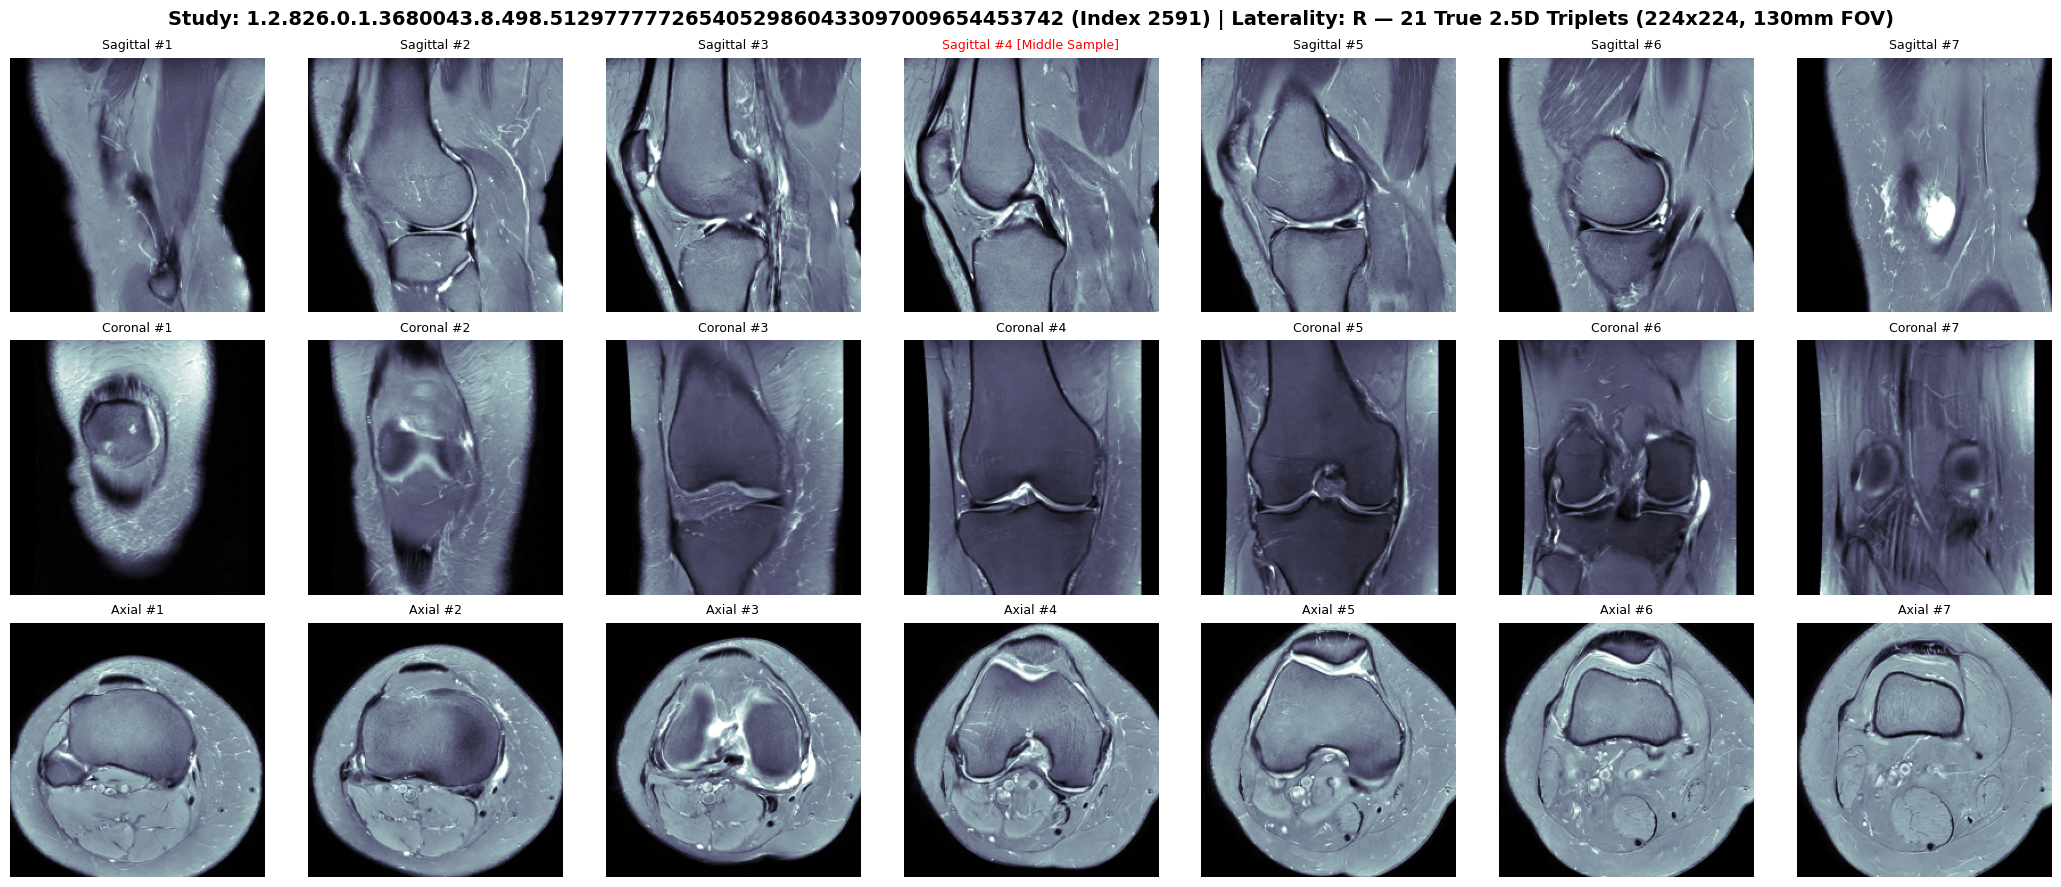


🏆 DATASET PREPROCESSING (V3.0 - 21 TRIPLETS @ 224px) COMPLETE!
📌 Next Steps on Kaggle:
   1. Click "Save Version" -> Select "Save & Run All (Commit)"
   2. After completion, go to Notebook Output -> Click "+ New Dataset"
   3. Name it (e.g. "rsna-preprocessing-data-v3") and click Create
   4. Attach that dataset to your Training Notebooks for upgraded SOTA training!


In [7]:
# =========================================================================
# 7. Verification & Visual Inspection
# =========================================================================

print('🔍 Testing Memory-Mapped Loading of Saved True 2.5D Dataset...')
mmap_test = np.load(npy_out_path, mmap_mode='r')
meta_test = pd.read_csv(meta_out_path)

assert mmap_test.shape == (len(meta_test), CFG.total_slices, CFG.channels, CFG.img_size, CFG.img_size)
print(f'✅ Verification PASSED: Shape {mmap_test.shape} strictly matches {len(meta_test)} studies.')

# ── SECTION 1: 100% Comprehensive Metadata Quality Audit ──────────────────
n_total = len(meta_test)
n_prim = int(meta_test['processing_success'].sum()) if 'processing_success' in meta_test.columns else 0
n_full = int(meta_test['full_protocol_success'].sum()) if 'full_protocol_success' in meta_test.columns else 0
total_read_errs = int(meta_test['dcm_read_errors'].sum()) if 'dcm_read_errors' in meta_test.columns else 0
studies_with_errs = int((meta_test['dcm_read_errors'] > 0).sum()) if 'dcm_read_errors' in meta_test.columns else 0
subopt_studies = int(((meta_test.get('sag_is_suboptimal', 0) == 1) | 
                      (meta_test.get('cor_is_suboptimal', 0) == 1) | 
                      (meta_test.get('axi_is_suboptimal', 0) == 1)).sum())

print(f'\n=========================================================================')
print(f'📊 SECTION 1: 100% FULL-DATASET METADATA AUDIT (N={n_total:,} studies)')
print(f'=========================================================================')
print(f'• Primary Diagnostic Complete (Sag+Cor >= 7 slices): {n_prim:,} ({n_prim/max(1, n_total)*100.0:.2f}%)')
print(f'• Full 3-Plane Complete (Sag+Cor+Axi >= 7 slices):    {n_full:,} ({n_full/max(1, n_total)*100.0:.2f}%)')
if 'num_missing_planes' in meta_test.columns:
    print(f'• Missing Plane Distribution:')
    for n_miss, count in meta_test['num_missing_planes'].value_counts().sort_index().items():
        print(f'   - Missing {n_miss} planes: {count:,} studies ({count/n_total*100.0:.1f}%)')
print(f'• Per-Plane Diagnostic Availability (>= 7 distinct slices):')
print(f'   - Sagittal Available:          {meta_test["sag_available"].sum():,} / {n_total:,} ({meta_test["sag_available"].mean():.1%})')
print(f'   - Coronal Available:           {meta_test["cor_available"].sum():,} / {n_total:,} ({meta_test["cor_available"].mean():.1%})')
print(f'   - Axial Available:             {meta_test["axi_available"].sum():,} / {n_total:,} ({meta_test["axi_available"].mean():.1%})')
print(f'• Suboptimal Fallback Series:      {subopt_studies:,} studies ({subopt_studies/max(1, n_total)*100.0:.1f}%) contain repeat/motion fallback')
print(f'• DICOM Read / Decode Errors:      {total_read_errs:,} corrupt slices across {studies_with_errs:,} studies')

# ── SECTION 2: 100% ALL-SLICE Memmap Zero-Pixel Audit (All 21 Slices x All Studies) ─
print(f'\n=========================================================================')
print(f'📊 SECTION 2: 100% ALL-SLICE FULL-DATASET MEMMAP AUDIT (92,547 Slices)')
print(f'=========================================================================')
print(f'Scanning all 21 slices across 100% ({n_total:,}) studies via short-circuit evaluation...')

plane_slice_ranges = {'Sagittal': (0, 7), 'Coronal': (7, 14), 'Axial': (14, 21)}
zero_slice_anomalies = {'Sagittal': 0, 'Coronal': 0, 'Axial': 0}
studies_with_blank_slices = 0

for i in range(n_total):
    row = meta_test.iloc[i]
    study_has_blank_slice = False
    for pname, (s_start, s_end) in plane_slice_ranges.items():
        avail_col = f'{pname.lower()[:3]}_available'
        if row.get(avail_col, 0) == 1:
            # Check every single slice in the plane: np.any() short-circuits instantly on non-zero
            for s in range(s_start, s_end):
                if not np.any(mmap_test[i, s] > 0):
                    zero_slice_anomalies[pname] += 1
                    study_has_blank_slice = True
    if study_has_blank_slice:
        studies_with_blank_slices += 1

all_slices_clean = True
for pname, z_cnt in zero_slice_anomalies.items():
    if z_cnt > 0:
        print(f'   ⚠️ ANOMALY: Found {z_cnt} individual slices in {pname} that are completely all-zero!')
        all_slices_clean = False
if all_slices_clean:
    print(f'   ✅ 100% Slice Integrity PASSED: 0 of 92,547 available slice positions are all-zero.')

# ── SECTION 3: Seeded Representative Slice Diversity & Quality Audit ──────
print(f'\n=========================================================================')
print(f'📊 SECTION 3: DETERMINISTIC SEEDED SLICE DIVERSITY AUDIT (N=200, seed=42)')
print(f'=========================================================================')
np.random.seed(42)
sample_size = min(200, n_total)
check_indices = np.random.choice(n_total, size=sample_size, replace=False)

plane_ranges = {'Sagittal': (0, 7), 'Coronal': (7, 14), 'Axial': (14, 21)}
duplicate_slice_warnings = 0

for idx in check_indices:
    row = meta_test.iloc[idx]
    vol = mmap_test[idx]  # (21, 3, 224, 224)
    
    for pname, (s_idx, e_idx) in plane_ranges.items():
        avail_col = f'{pname.lower()[:3]}_available'
        if row.get(avail_col, 0) == 1:
            for s in range(s_idx, e_idx - 1):
                # Compare middle channel of consecutive triplets
                if np.array_equal(vol[s, 1], vol[s + 1, 1]):
                    duplicate_slice_warnings += 1

if duplicate_slice_warnings > 0:
    print(f'   ⚠️ WARNING: Encountered {duplicate_slice_warnings} identical consecutive slice pairs across sample.')
else:
    print(f'   ✅ Slice Diversity PASSED: 100% distinct consecutive slices across sampled volumes.')

# Visualize Slices from a Random Study
sample_idx = np.random.randint(0, len(meta_test))
sample_row = meta_test.iloc[sample_idx]
sample_study = sample_row['StudyInstanceUID']
sample_lat = sample_row.get('Laterality', 'Unknown')
sample_vol = mmap_test[sample_idx]  # (21, 3, 224, 224)

fig, axes = plt.subplots(3, 7, figsize=(21, 9))
plane_names = ['Sagittal', 'Coronal', 'Axial']

for p in range(3):
    for s in range(7):
        slice_idx = p * 7 + s
        center_channel = sample_vol[slice_idx, 1]
        axes[p, s].imshow(center_channel, cmap='bone')
        is_center_acl = (p == 0 and s == 3)
        title_color = 'red' if is_center_acl else 'black'
        title_tag = ' [Middle Sample]' if is_center_acl else ''
        axes[p, s].set_title(f'{plane_names[p]} #{s+1}{title_tag}', fontsize=9, color=title_color)
        axes[p, s].axis('off')

plt.suptitle(f'Study: {sample_study} (Index {sample_idx}) | Laterality: {sample_lat} — 21 True 2.5D Triplets ({CFG.img_size}x{CFG.img_size}, 130mm FOV)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n🏆 DATASET PREPROCESSING (V3.0 - 21 TRIPLETS @ 224px) COMPLETE!')
print('📌 Next Steps on Kaggle:')
print('   1. Click "Save Version" -> Select "Save & Run All (Commit)"')
print('   2. After completion, go to Notebook Output -> Click "+ New Dataset"')
print('   3. Name it (e.g. "rsna-preprocessing-data-v3") and click Create')
print('   4. Attach that dataset to your Training Notebooks for upgraded SOTA training!')
